In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import hashlib
import os

# Define relative paths based on the experiment/ directory structure
DATA_PATH = "../data/raw/cohort.parquet"
GENERATE_SCRIPT = "../src/synthetic/generate_cohort.py"
VALIDATE_SCRIPT = "../src/synthetic/validate.py"

In [9]:
# Run the pipeline to generate the synthetic cohort
print("Executing Synthetic Cohort Generation Pipeline...")
!python {GENERATE_SCRIPT}

Executing Synthetic Cohort Generation Pipeline...
🚀 INITIATING MODULAR SYNTHETIC COHORT GENERATION PIPELINE...
🧬 Generating Demographics and Biomarkers...
🧬 Computing FHRS Scores...
🦠 Injecting Disease Logits & Outcomes...
⏳ Expanding to Longitudinal Visits...
🔁 Updating Outcomes Across Visits (incident diagnosis)...
🕳️ Injecting Clinical Missingness...

✅ MODULAR SYNTHESIS COMPLETE!
📊 Total Encounters: 23996 | Unique Patients: 15000
📁 Output: experiment/data/raw/cohort.parquet
🔒 SHA-256 Digest: e98d963a4ff54e9f664cf5dfe8afce7204adbb8510cc9a7f5cf2661742f7bfb2


In [10]:
# Load the generated parquet file
df = pd.read_parquet(DATA_PATH)
print(f"Cohort loaded successfully! Shape: {df.shape} (Patients/Visits x Features)")
display(df.head())

Cohort loaded successfully! Shape: (23996, 51) (Patients/Visits x Features)


,patient_id,biological_sex,age,bmi,systolic_bp,diastolic_bp,resting_hr,total_cholesterol,hdl,ldl,...,tg_measured,fpg_measured,resting_hr_measured,total_cholesterol_measured,diastolic_bp_measured,bmi_measured,fev1_measured,gad7_measured,phq9_measured,spo2_measured
0,PT-20260000,0,59,NaN,127.181018,87.984248,NaN,182.271499,74.189464,88.082035,...,0,1,0,1,1,0,1,0,0,1
1,PT-20260000,0,60,NaN,127.781018,87.984248,79.334462,182.271499,74.189464,88.082035,...,0,0,1,1,1,0,0,0,0,1
2,PT-20260001,1,68,33.711067,147.506693,111.793817,NaN,181.490764,70.126938,NaN,...,0,1,0,1,1,1,0,1,1,0
3,PT-20260002,0,34,28.311441,101.535904,61.620583,NaN,NaN,82.238886,NaN,...,1,0,0,0,1,1,0,0,1,1
4,PT-20260002,0,35,NaN,102.135904,61.620583,NaN,182.422711,82.238886,NaN,...,0,0,0,1,1,0,0,0,0,0


<Figure size 1200x600 with 0 Axes>

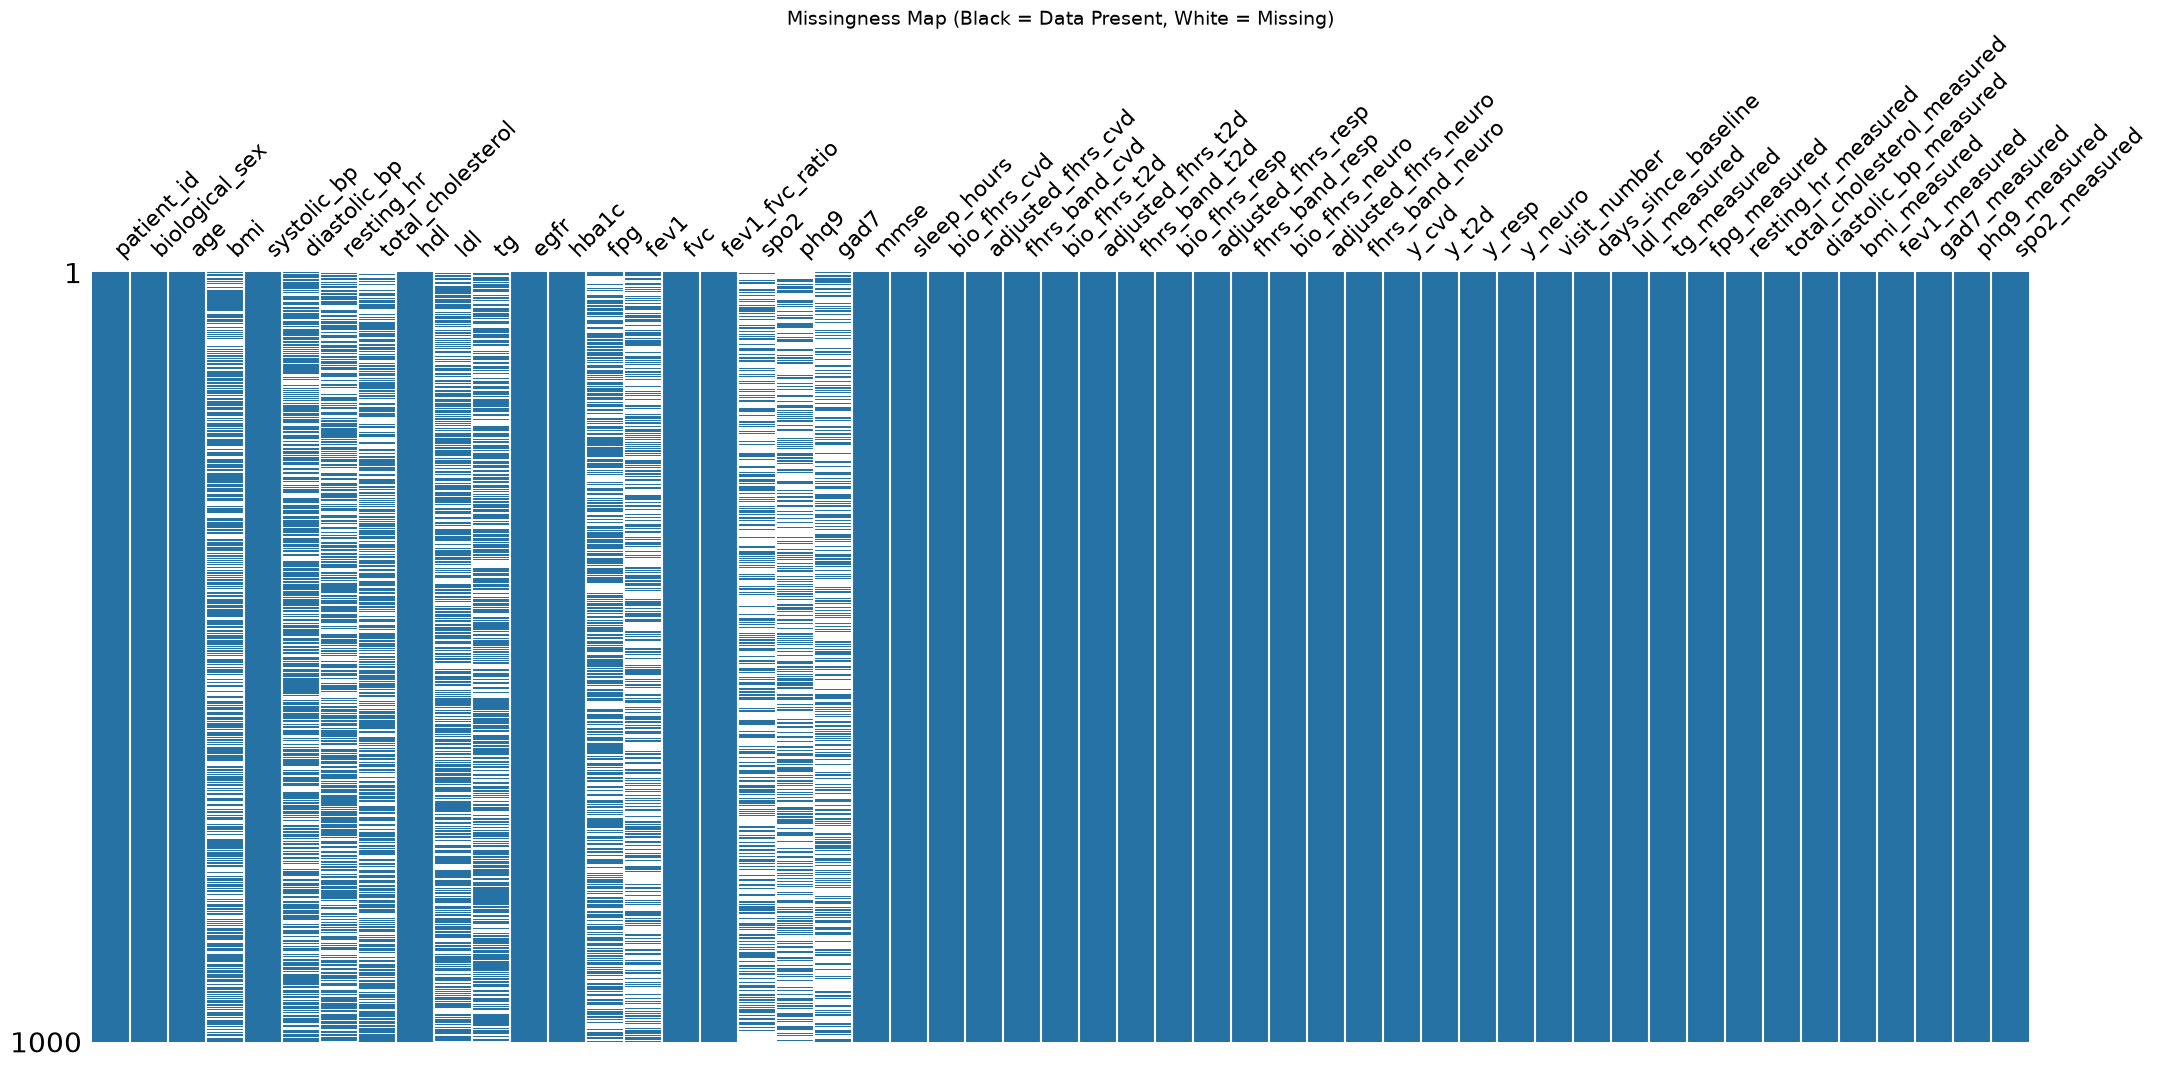

In [11]:
# Verifies Gate 8: Missingness boundaries (0% for baseline, <40% routine, <60% specialized)
plt.figure(figsize=(12, 6))
# Sampling 1000 rows to keep the rendering fast
msno.matrix(df.sample(min(1000, len(df))), labels=True, sparkline=False, color=(0.15, 0.45, 0.65))
plt.title("Missingness Map (Black = Data Present, White = Missing)", fontsize=14)
plt.show()

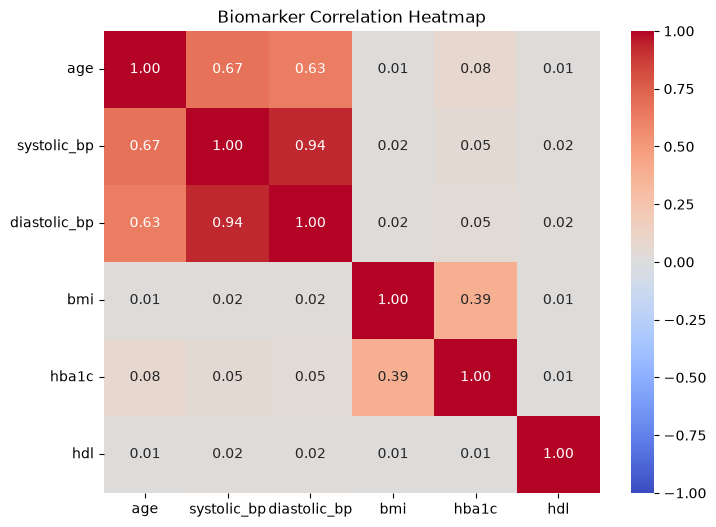

In [12]:
# Verifies Gate 3: Biological correlation integrity (e.g., age vs SBP, BMI vs HbA1c)
# Note: Add or remove columns based on what your distributions.py currently generates
target_cols = ['age', 'systolic_bp', 'diastolic_bp', 'bmi', 'hba1c', 'hdl', 'triglycerides']
available_cols = [c for c in target_cols if c in df.columns]

if available_cols:
    plt.figure(figsize=(8, 6))
    corr_matrix = df[available_cols].corr()
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0, fmt=".2f")
    plt.title("Biomarker Correlation Heatmap")
    plt.show()
else:
    print("Warning: Target columns for correlation not yet generated.")

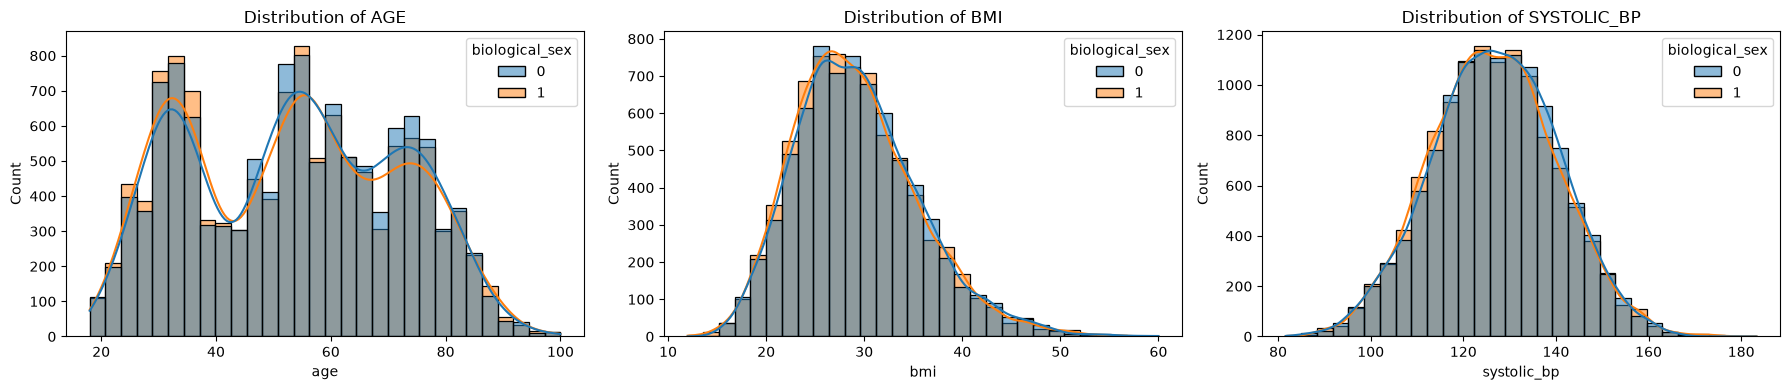

In [13]:
# Verifies Gate 2: Distribution shapes against NHANES/clinical bounds
dist_cols = ['age', 'bmi', 'systolic_bp']
available_dist_cols = [c for c in dist_cols if c in df.columns]

if available_dist_cols:
    fig, axes = plt.subplots(1, len(available_dist_cols), figsize=(18, 4))
    if len(available_dist_cols) == 1:
        axes = [axes]
        
    for ax, col in zip(axes, available_dist_cols):
        # Using biological_sex as hue if it exists
        hue_col = 'biological_sex' if 'biological_sex' in df.columns else None
        sns.histplot(data=df, x=col, hue=hue_col, kde=True, ax=ax, bins=30)
        ax.set_title(f"Distribution of {col.upper()}")
        
    plt.tight_layout()
    plt.show()

In [14]:
def get_sha256(filepath):
    hasher = hashlib.sha256()
    with open(filepath, 'rb') as f:
        hasher.update(f.read())
    return hasher.hexdigest()

# 1. Hash the first run
hash_run_1 = get_sha256(DATA_PATH)
print(f"Run 1 SHA-256 Digest: {hash_run_1}")

# 2. Generate the cohort a second time
print("\nExecuting Run 2 to test cryptographic determinism (SEED=42)...")
!python {GENERATE_SCRIPT}

# 3. Hash the second run
hash_run_2 = get_sha256(DATA_PATH)
print(f"Run 2 SHA-256 Digest: {hash_run_2}\n")

# 4. Compare
if hash_run_1 == hash_run_2:
    print("✅ PASS: Cryptographic determinism verified. Digests match perfectly.")
else:
    print("❌ FAIL: Digests do not match! Check your stochastic generators for unseeded randomness.")

Run 1 SHA-256 Digest: e98d963a4ff54e9f664cf5dfe8afce7204adbb8510cc9a7f5cf2661742f7bfb2

Executing Run 2 to test cryptographic determinism (SEED=42)...
🚀 INITIATING MODULAR SYNTHETIC COHORT GENERATION PIPELINE...
🧬 Generating Demographics and Biomarkers...
🧬 Computing FHRS Scores...
🦠 Injecting Disease Logits & Outcomes...
⏳ Expanding to Longitudinal Visits...
🔁 Updating Outcomes Across Visits (incident diagnosis)...
🕳️ Injecting Clinical Missingness...

✅ MODULAR SYNTHESIS COMPLETE!
📊 Total Encounters: 23996 | Unique Patients: 15000
📁 Output: experiment/data/raw/cohort.parquet
🔒 SHA-256 Digest: e98d963a4ff54e9f664cf5dfe8afce7204adbb8510cc9a7f5cf2661742f7bfb2
Run 2 SHA-256 Digest: e98d963a4ff54e9f664cf5dfe8afce7204adbb8510cc9a7f5cf2661742f7bfb2

✅ PASS: Cryptographic determinism verified. Digests match perfectly.
